In [1]:
using Plots
using Distributions, Random, Statistics
using LinearAlgebra, SparseArrays, JSON
using Colors
using CSV
using DataFrames
using MLJ
using Dates
using JuMP, Ipopt
using LinearAlgebra

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

In [ ]:
# Physics Based Model
# Data from the kaggle data set 
# This model only includes physical features. This model does not include any correlation of varaibles based on time
# Variables for prediction: windspeed 10m, windspeed 100m, windgusts 10m

# Load data
df = CSV.read("location1.csv", DataFrame; types = Dict(:Time => String))
df.Time = DateTime.(df.Time, dateformat"yyyy-mm-dd HH:MM:SS")

# Normalize features
m     = nrow(df)
times = df.Time
t     = Float64.(df.Power)
x10m  = Float64.(df.windspeed_10m)  ./ 10.0
x100m = Float64.(df.windspeed_100m) ./ 10.0
x10g  = Float64.(df.windgusts_10m) ./ 10.0

# Generate training/validation/testing split
train, val, test = partition(eachindex(t), 0.8, 0.1; shuffle = false, rng = 128)

# Generate RBF centers based on features
c_max = max(1.1, maximum(x10m), maximum(x100m)) + 0.05
c = collect(0.0:0.05:c_max)
num_centers = length(c)

# RBF features for one input
function rbf_features(xs, γ)
    Φ = zeros(length(xs), num_centers)
    for i in eachindex(xs), j in 1:num_centers
        Φ[i, j] = exp(-(γ * abs(xs[i] - c[j]))^2)
    end
    return Φ
end

# Combines all three features into matrix at each time stamp
design_matrix(x1, x2, x3, γ) = hcat(rbf_features(x1, γ), rbf_features(x2, γ), rbf_features(x3, γ))

# Stochastic Gradient Descent loop
function train_rbf(Φ, t; α = 0.01, n_epochs = 20, λ = 0.001,reg_type = :l2, seed = 128) reg_type in (:l2, :l1, :none) ||error("reg_type must be :l2, :l1, or :none, got $reg_type")

    rng    = MersenneTwister(seed)
    ntrain = size(Φ, 1)
    nfeat  = size(Φ, 2)
    w_0    = 0.0
    w      = zeros(nfeat)

    for epoch in 1:n_epochs
        for i in shuffle(rng, 1:ntrain)       # each sample visited once per epoch
            ϕi  = @view Φ[i, :]               # no allocation
            err = (w_0 + dot(ϕi, w)) - t[i]

            w_0 -= α * err
            w   .-= α * err .* ϕi

            if reg_type == :l2
                w .-= α * λ .* w
            elseif reg_type == :l1
                w .= sign.(w) .* max.(0, abs.(w) .- α * λ)
            end
        end
    end
    return w_0, w
end

# Create function based on features
predict_rbf(Φ, w_0, w) = w_0 .+ Φ * w

predict_rbf (generic function with 1 method)

In [ ]:
# Validaiton
# Test different hyperparameter values
λ_grid = [5e-4, 2e-4, 1e-4, 7.5e-5, 5e-5]
γ_grid = [ 4.0, 4.5, 5.0, 6.0, 7.0,]

best = (rmse = Inf, λ = NaN, γ = NaN)
for γ in γ_grid, λ in λ_grid
    Φ_train = design_matrix(x10m[train], x100m[train], x10g[train], γ)
    Φ_val   = design_matrix(x10m[val],   x100m[val], x10g[val],  γ)
    w_0, w  = train_rbf(Φ_train, t[train]; λ = λ)
    score   = rmse(predict_rbf(Φ_val, w_0, w), t[val])
    println("γ = $γ, λ = $λ → val RMSE = $(round(score, digits = 4))")
    if score < best.rmse
        global best = (rmse = score, λ = λ, γ = γ)
    end
end
println("Best: ", best)

# Once best fit is evaluated, train a model using the best hyperparameter configurations
γ, λ = best.γ, best.λ
Φ_train = design_matrix(x10m[train], x100m[train], x10g[train], γ);
w_0, w  = train_rbf(Φ_train, t[train]; λ = λ);
Φ_test = design_matrix(x10m[test], x100m[test], x10g[test], γ);

γ = 4.0, λ = 0.0005 → val RMSE = 0.1718
γ = 4.0, λ = 0.0002 → val RMSE = 0.1718
γ = 4.0, λ = 0.0001 → val RMSE = 0.1718
γ = 4.0, λ = 7.5e-5 → val RMSE = 0.1719
γ = 4.0, λ = 5.0e-5 → val RMSE = 0.1719
γ = 4.5, λ = 0.0005 → val RMSE = 0.1713
γ = 4.5, λ = 0.0002 → val RMSE = 0.1714
γ = 4.5, λ = 0.0001 → val RMSE = 0.1714
γ = 4.5, λ = 7.5e-5 → val RMSE = 0.1714
γ = 4.5, λ = 5.0e-5 → val RMSE = 0.1714
γ = 5.0, λ = 0.0005 → val RMSE = 0.1709
γ = 5.0, λ = 0.0002 → val RMSE = 0.1709
γ = 5.0, λ = 0.0001 → val RMSE = 0.171
γ = 5.0, λ = 7.5e-5 → val RMSE = 0.171
γ = 5.0, λ = 5.0e-5 → val RMSE = 0.171
γ = 6.0, λ = 0.0005 → val RMSE = 0.1703
γ = 6.0, λ = 0.0002 → val RMSE = 0.1703
γ = 6.0, λ = 0.0001 → val RMSE = 0.1703
γ = 6.0, λ = 7.5e-5 → val RMSE = 0.1703
γ = 6.0, λ = 5.0e-5 → val RMSE = 0.1703
γ = 7.0, λ = 0.0005 → val RMSE = 0.1702
γ = 7.0, λ = 0.0002 → val RMSE = 0.1702
γ = 7.0, λ = 0.0001 → val RMSE = 0.1702
γ = 7.0, λ = 7.5e-5 → val RMSE = 0.1702
γ = 7.0, λ = 5.0e-5 → val RMSE = 0.1702
Bes

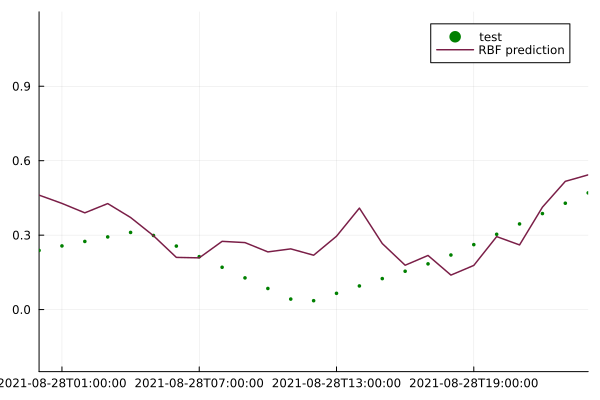

In [18]:
# Plot testing data for the best model determined from validation
ŷ = predict_rbf(design_matrix(x10m, x100m, x10g, γ), w_0, w)

# Select a random testing day
test_day = Date(times[rand(test)])

day_start = DateTime(test_day)
day_end   = day_start + Day(1)

# Plot training and testing data
plo = plot(legend = :topright)
scatter!(plo, times[test], t[test],c = :green, ms = 2,markerstrokewidth = 0, label = "test")
plot!(plo, times, ŷ,lw = 1.5, c = purple, label = "RBF prediction")
plot!(plo, ylims = (-0.25, 1.2))
plot!(plo, xlims = (day_start, day_end))
display(plo)